## 1. Khai báo thư viện

Import thư viện xử lý dữ liệu, kiểm định và trực quan hóa. Chọn α = 0,05 và tạo thư mục lưu kết quả.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from itertools import combinations
from scipy import stats
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests
from IPython.display import display
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

sns.set_theme(style="whitegrid")
ALPHA = 0.05

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

OUT_DIR = ROOT / "outputs"
OUT = OUT_DIR / "02_Hypothesis_Correlation"
FIG = OUT / "figures"
TABLE = OUT / "tables"
DATA_PATH = Path("../outputs/cleaned_traffic.csv")

FIG.mkdir(parents=True, exist_ok=True)
TABLE.mkdir(parents=True, exist_ok=True)


def save_plot(filename):
    plt.tight_layout()
    plt.savefig(FIG / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close()

    print("Thư mục hiện tại:", Path.cwd())

from pathlib import Path

print("Thư mục làm việc hiện tại:", Path.cwd())
print("ROOT hiện tại:", ROOT)

Thư mục làm việc hiện tại: c:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175\notebooks
ROOT hiện tại: c:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175


## 2. Đọc và kiểm tra dữ liệu

Đọc dữ liệu đã làm sạch, kiểm tra giá trị thiếu và thời điểm trùng lặp. Khi tính tương quan, loại giá trị thiếu theo từng cặp biến.


In [2]:
df = pd.read_csv(DATA_PATH)

df["date_time"] = pd.to_datetime(
    df["date_time"], errors="coerce"
)

numeric_cols = [
    "traffic_volume", "temp_c",
    "rain_1h", "snow_1h", "clouds_all"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Kich thuoc du lieu:", df.shape)
print("So thoi diem trung:", df["date_time"].duplicated().sum())

display(
    df[["date_time"] + numeric_cols]
    .isna().sum().to_frame("missing")
)

# Dung lai neu du lieu khong dap ung dieu kien dau vao
if df["date_time"].isna().any():
    raise ValueError("Co thoi gian khong hop le. Can kiem tra voi TV1.")

if df["date_time"].duplicated().any():
    raise ValueError("Co thoi diem trung. Can kiem tra voi TV1.")

if df["traffic_volume"].isna().any():
    raise ValueError("Traffic volume bi thieu. Can kiem tra voi TV1.")

if not df["date_time"].eq(df["date_time"].dt.floor("h")).all():
    raise ValueError("Co thoi diem khong nam dung moc gio.")

df = df.sort_values("date_time").reset_index(drop=True)

display(df.head())

Kich thuoc du lieu: (40575, 17)
So thoi diem trung: 0


,missing
date_time,0
traffic_volume,0
temp_c,10
rain_1h,1
snow_1h,0
clouds_all,0


,date_time,temp,rain_1h,snow_1h,clouds_all,traffic_volume,weather_main,holiday,weather_description,hour,day_of_week,month,year,is_weekend,temp_c,is_holiday,time_period
0,2012-10-02 09:00:00,288.28,0.0,0.0,40.0,5545,Clouds,NaN,scattered clouds,9,1,10,2012,0,15.13,0,Sang (6-11)
1,2012-10-02 10:00:00,289.36,0.0,0.0,75.0,4516,Clouds,NaN,broken clouds,10,1,10,2012,0,16.21,0,Sang (6-11)
2,2012-10-02 11:00:00,289.58,0.0,0.0,90.0,4767,Clouds,NaN,overcast clouds,11,1,10,2012,0,16.43,0,Sang (6-11)
3,2012-10-02 12:00:00,290.13,0.0,0.0,90.0,5026,Clouds,NaN,overcast clouds,12,1,10,2012,0,16.98,0,Chieu (12-17)
4,2012-10-02 13:00:00,291.14,0.0,0.0,75.0,4918,Clouds,NaN,broken clouds,13,1,10,2012,0,17.99,0,Chieu (12-17)


## 3. Nhóm thời tiết và tổng hợp dữ liệu theo ngày

Tính lưu lượng trung bình theo giờ trong ngày, đơn vị xe/giờ.
Chỉ giữ ngày có đủ 24 bản ghi giờ.

Các nhãn thời tiết ghép như Rain | Mist được tách theo dấu |.
Mỗi giờ được phân vào một nhóm theo thứ tự ưu tiên:
- Precipitation: có Rain, Drizzle, Snow, Thunderstorm hoặc Squall.
- Low visibility: không thuộc nhóm trên và có Mist, Fog, Haze hoặc Smoke.
- Clouds: có Clouds và không thuộc hai nhóm trên.
- Clear: có Clear và không thuộc các nhóm trên.
- Other: hiện tượng còn lại.
- Unknown: thiếu nhãn thời tiết.

Nhóm đại diện ngày là nhóm xuất hiện nhiều nhất trong ngày.
Nếu hòa, ưu tiên theo thứ tự Precipitation, Low visibility,
Clouds, Clear, Other, Unknown.

Quy tắc này được áp dụng thống nhất, không lựa chọn dựa trên p-value.

In [3]:
weather_priority = [
    "Precipitation",
    "Low visibility",
    "Clouds",
    "Clear",
    "Other",
    "Unknown"
]


def classify_weather(value):
    # Xử lý nhãn thiếu
    if pd.isna(value) or not str(value).strip():
        return "Unknown"

    # Tách cả nhãn đơn và nhãn ghép
    tokens = {
        item.strip()
        for item in str(value).split("|")
        if item.strip()
    }

    precipitation = {
        "Rain", "Drizzle", "Snow",
        "Thunderstorm", "Squall"
    }

    low_visibility = {
        "Mist", "Fog", "Haze", "Smoke"
    }

    if tokens & precipitation:
        return "Precipitation"

    if tokens & low_visibility:
        return "Low visibility"

    if "Clouds" in tokens:
        return "Clouds"

    if "Clear" in tokens:
        return "Clear"

    return "Other"


def get_weather_mode(series):
    counts = series.value_counts()

    if counts.empty:
        return "Unknown"

    tied_groups = set(
        counts[counts == counts.max()].index
    )

    return next(
        group
        for group in weather_priority
        if group in tied_groups
    )


# Nhóm thời tiết từng giờ trước khi tổng hợp ngày
df["weather_group"] = df["weather_main"].apply(
    classify_weather
)

df["date"] = df["date_time"].dt.normalize()

daily = (
    df.groupby("date", as_index=False)
    .agg(
        daily_mean=("traffic_volume", "mean"),
        hours_observed=("traffic_volume", "size"),
        weather_group=("weather_group", get_weather_mode)
    )
)

daily24 = daily.loc[
    daily["hours_observed"] == 24
].copy()

if daily24.empty:
    raise ValueError("Không có ngày đủ 24 bản ghi giờ.")

daily24["day_num"] = daily24["date"].dt.dayofweek
daily24["day_of_week"] = daily24["date"].dt.day_name()

daily24["day_type"] = np.where(
    daily24["day_num"] >= 5,
    "Weekend",
    "Weekday"
)

print("Tổng số ngày có quan sát:", len(daily))
print("Số ngày đủ 24 giờ:", len(daily24))
print("Số ngày không sử dụng:", len(daily) - len(daily24))

display(
    daily24["day_type"]
    .value_counts()
    .to_frame("n_days")
)

display(
    daily24["weather_group"]
    .value_counts()
    .to_frame("n_days")
)

display(daily24.head())

# Lưu bảng đối chiếu cách nhóm thời tiết
weather_mapping = (
    df[["weather_main", "weather_group"]]
    .drop_duplicates()
    .sort_values(["weather_group", "weather_main"])
)

weather_mapping.to_csv(
    TABLE / "weather_group_mapping.csv",
    index=False
)

daily24.to_csv(
    TABLE / "daily24_data.csv",
    index=False
)

Tổng số ngày có quan sát: 1860
Số ngày đủ 24 giờ: 1214
Số ngày không sử dụng: 646


,n_days
day_type,
Weekday,859
Weekend,355


,n_days
weather_group,
Clouds,462
Clear,415
Precipitation,196
Low visibility,141


,date,daily_mean,hours_observed,weather_group,day_num,day_of_week,day_type
2,2012-10-04,3747.458333,24,Clear,3,Thursday,Weekday
6,2012-10-08,3422.291667,24,Clouds,0,Monday,Weekday
11,2012-10-13,2937.500000,24,Clear,5,Saturday,Weekend
12,2012-10-14,2432.958333,24,Low visibility,6,Sunday,Weekend
13,2012-10-15,3546.125000,24,Low visibility,0,Monday,Weekday


## 3.1 Kiểm tra sự phụ thuộc theo thời gian

Dữ liệu lưu lượng giao thông được thu thập theo thời gian nên các ngày gần nhau có thể có mức lưu lượng tương tự. Điều này có thể ảnh hưởng đến giả định độc lập của các kiểm định thống kê ở những phần tiếp theo.

Nhóm sử dụng biểu đồ chuỗi thời gian, hàm tự tương quan (ACF) và kiểm định Ljung–Box để khảo sát sự phụ thuộc theo thời gian của lưu lượng giao thông trung bình ngày.

Số ngày đủ 24 giờ: 1214
Ngày bắt đầu: 2012-10-04 00:00:00
Ngày kết thúc: 2018-09-30 00:00:00


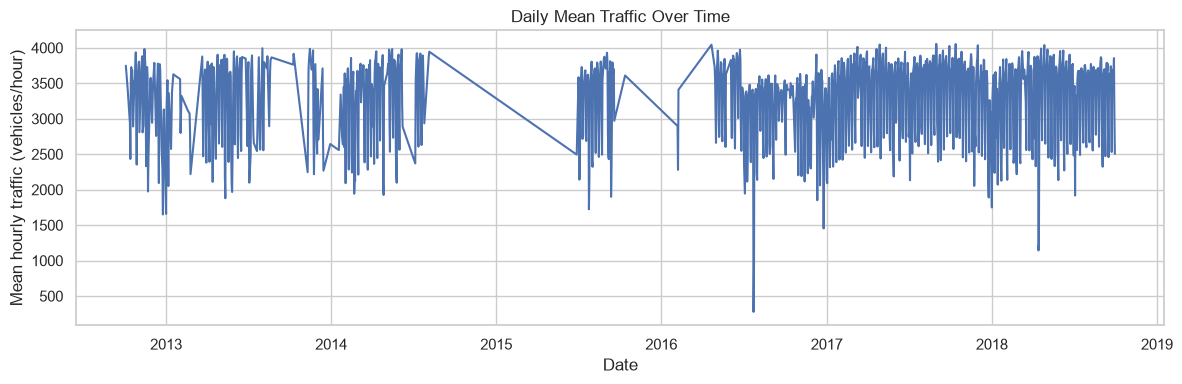

Thư mục hiện tại: c:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175\notebooks


<Figure size 1000x400 with 0 Axes>

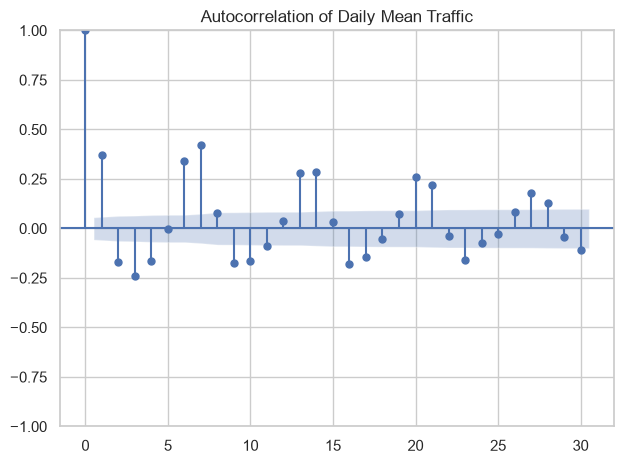

Thư mục hiện tại: c:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175\notebooks


In [4]:
daily_ts = (
    daily24[["date", "daily_mean"]]
    .sort_values("date")
    .set_index("date")["daily_mean"]
)

print("Số ngày đủ 24 giờ:", len(daily_ts))
print("Ngày bắt đầu:", daily_ts.index.min())
print("Ngày kết thúc:", daily_ts.index.max())

# Vẽ chuỗi thời gian
plt.figure(figsize=(12, 4))
plt.plot(daily_ts.index, daily_ts.values)
plt.title("Daily Mean Traffic Over Time")
plt.xlabel("Date")
plt.ylabel("Mean hourly traffic (vehicles/hour)")
save_plot("daily_traffic_time_series.png")

# Vẽ tự tương quan của chuỗi
plt.figure(figsize=(10, 4))
plot_acf(daily_ts, lags=30, missing="drop")
plt.title("Autocorrelation of Daily Mean Traffic")
save_plot("daily_traffic_acf.png")


In [5]:
# Kiểm tra tự tương quan tổng thể đến độ trễ 7 và 14 ngày
lb = acorr_ljungbox(
    daily_ts,
    lags=[7, 14],
    return_df=True
)

display(lb)


,lb_stat,lb_pvalue
7,666.000538,1.471021e-139
14,951.583704,3.792220e-194


In [6]:
#tao 2 nhom du lieu
weekday = daily24.loc[
    daily24["day_type"] == "Weekday", "daily_mean"
].dropna()

weekend = daily24.loc[
    daily24["day_type"] == "Weekend", "daily_mean"
].dropna()

# Kiem tra so quan sat va phan phoi cua 2 nhom
print("Số ngày thường:", len(weekday))
print("Số ngày cuối tuần:", len(weekend))

# Shapiro-Wilk dùng để kiểm tra tính chuẩn,
# không phải điều kiện duy nhất để quyết định có dùng Welch t-test.
# Với mẫu lớn, kiểm định này có thể rất nhạy với sai lệch nhỏ.
for name, values in [
    ("Ngày thường", weekday),
    ("Cuối tuần", weekend)
]:
    if 3 <= len(values) <= 5000:
        shapiro = stats.shapiro(values)
        print(
            f"{name}: Shapiro-Wilk W={shapiro.statistic:.4f}, "
            f"p={shapiro.pvalue:.4g}"
        )


Số ngày thường: 859
Số ngày cuối tuần: 355
Ngày thường: Shapiro-Wilk W=0.7658, p=3.133e-33
Cuối tuần: Shapiro-Wilk W=0.9207, p=9.448e-13


## 4. Welch t-test giữa ngày thường và cuối tuần


**Câu hỏi nghiên cứu:** Lưu lượng giao thông trung bình theo ngày có khác nhau giữa ngày thường (thứ Hai–thứ Sáu) và cuối tuần (thứ Bảy–Chủ nhật) không?

**Giả thuyết thống kê**

- H₀: Trung bình lưu lượng giao thông của hai nhóm bằng nhau.
- H₁: Trung bình lưu lượng giao thông của hai nhóm khác nhau.
- Mức ý nghĩa: α = 0,05.

**Lý do chọn kiểm định**

Welch independent t-test được sử dụng để so sánh trung bình của hai nhóm độc lập và không yêu cầu phương sai hai nhóm bằng nhau.

**Điều kiện và hạn chế**

1. Biến kết quả `daily_mean` là biến định lượng.
2. Mỗi ngày chỉ thuộc một nhóm: ngày thường hoặc cuối tuần.
3. Các quan sát giữa hai nhóm cần độc lập. Tuy nhiên, lưu lượng của những ngày gần nhau có thể phụ thuộc theo thời gian.
4. Phân phối của biến trong từng nhóm nên được kiểm tra; cần lưu ý ngoại lệ. Welch t-test không yêu cầu phương sai hai nhóm bằng nhau.
5. Dữ liệu được tổng hợp từ các ngày có đủ 24 bản ghi giờ.

,n,mean,median,std
day_type,,,,
Weekday,859,3563.761496,3639.708333,358.827727
Weekend,355,2635.743192,2649.791667,366.318237


,t_statistic,df,p_value,mean_difference,CI95_lower,CI95_upper,cohens_d
0,40.391041,648.353713,3.474156e-179,928.018303,882.902254,973.134353,2.570463


p-value = 3.474e-179
Bac bo H0.


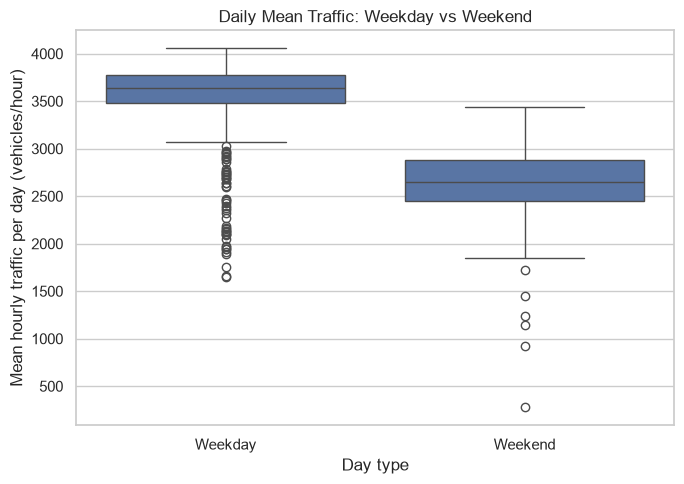

Thư mục hiện tại: c:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175\notebooks


In [7]:
weekday = daily24.loc[
    daily24["day_type"] == "Weekday", "daily_mean"
]

weekend = daily24.loc[
    daily24["day_type"] == "Weekend", "daily_mean"
]

summary = (
    daily24.groupby("day_type")["daily_mean"]
    .agg(n="count", mean="mean", median="median", std="std")
    .reindex(["Weekday", "Weekend"])
)

display(summary)

result = stats.ttest_ind(weekday, weekend, equal_var=False)

n1, n2 = len(weekday), len(weekend)
v1, v2 = weekday.var(ddof=1), weekend.var(ddof=1)

difference = weekday.mean() - weekend.mean()
se = np.sqrt(v1 / n1 + v2 / n2)

# Bac tu do Welch va khoang tin cay cho chenh lech
welch_df = (v1 / n1 + v2 / n2) ** 2 / (
    (v1 / n1) ** 2 / (n1 - 1)
    + (v2 / n2) ** 2 / (n2 - 1)
)

margin = stats.t.ppf(0.975, welch_df) * se

pooled_sd = np.sqrt(
    ((n1 - 1) * v1 + (n2 - 1) * v2) / (n1 + n2 - 2)
)

ttest_table = pd.DataFrame({
    "t_statistic": [result.statistic],
    "df": [welch_df],
    "p_value": [result.pvalue],
    "mean_difference": [difference],
    "CI95_lower": [difference - margin],
    "CI95_upper": [difference + margin],
    "cohens_d": [difference / pooled_sd]
})

display(ttest_table)

print(f"p-value = {result.pvalue:.4g}")
print("Bac bo H0." if result.pvalue < ALPHA
      else "Chua du bang chung bac bo H0.")

summary.to_csv(TABLE / "ttest_group_summary.csv")
ttest_table.to_csv(TABLE / "ttest_results.csv", index=False)

plt.figure(figsize=(7, 5))
sns.boxplot(
    data=daily24,
    x="day_type",
    y="daily_mean",
    order=["Weekday", "Weekend"]
)
plt.title("Daily Mean Traffic: Weekday vs Weekend")
plt.xlabel("Day type")
plt.ylabel("Mean hourly traffic per day (vehicles/hour)")
save_plot("ttest_boxplot.png")

### Nhận xét

Ngày thường có trung bình 3.563,76 xe/giờ, cao hơn cuối tuần khoảng 928,02 xe/giờ. Với p ≈ 3,47 × 10⁻¹⁷⁹ < 0,05, bác bỏ H₀. Khoảng tin cậy 95% cho chênh lệch là [882,90; 973,13] xe/giờ.

## 5. Welch ANOVA giữa bảy ngày trong tuần

Lưu lượng trung bình giữa các thứ có khác nhau không? Dùng Welch ANOVA để so sánh nhiều nhóm có thể khác phương sai; nếu có ý nghĩa, so sánh từng cặp và hiệu chỉnh Holm.

- H₀: Trung bình cả bảy nhóm bằng nhau.
- H₁: Có ít nhất một nhóm có trung bình khác.
- α = 0,05.

Boxplot giúp so sánh phân bố giữa các ngày.

,n,mean,median,std
day_of_week,,,,
Monday,179,3307.536778,3454.791667,429.306030
Tuesday,172,3556.747820,3636.083333,320.992409
Wednesday,163,3613.674335,3675.750000,243.564065
Thursday,172,3661.649709,3737.479167,317.625317
Friday,173,3691.495665,3771.625000,310.193158
Saturday,179,2820.030959,2867.250000,360.018693
Sunday,176,2448.314157,2490.645833,263.706724


,Levene_p,F_statistic,df_num,df_denom,p_value
0,0.015125,501.849655,6.0,535.698157,3.438263e-216


p-value ANOVA = 3.438e-216
Bac bo H0: Co it nhat mot nhom co trung binh khac.


,day_1,day_2,mean_difference,p_value,p_holm,significant
0,Monday,Tuesday,-249.211041,1.945175e-09,1.361623e-08,True
1,Monday,Wednesday,-306.137557,8.097814e-15,6.478251e-14,True
2,Monday,Thursday,-354.112931,7.508897e-17,6.758007e-16,True
3,Monday,Friday,-383.958886,1.651619e-19,1.651619e-18,True
4,Monday,Saturday,487.505819,1.195950e-26,1.435140e-25,True
5,Monday,Sunday,859.222621,4.938110e-67,6.913354e-66,True
6,Tuesday,Wednesday,-56.926516,6.752341e-02,2.025702e-01,False
7,Tuesday,Thursday,-104.901890,2.494406e-03,1.247203e-02,True
8,Tuesday,Friday,-134.747845,8.956518e-05,5.373911e-04,True
9,Tuesday,Saturday,736.716861,9.202179e-61,1.196283e-59,True


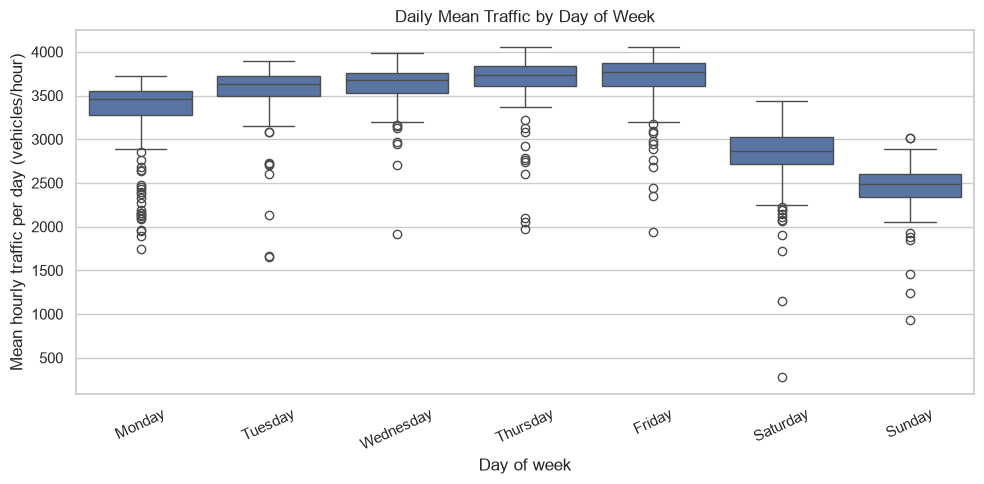

Thư mục hiện tại: c:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175\notebooks


In [8]:
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

samples = [
    daily24.loc[
        daily24["day_of_week"] == day, "daily_mean"
    ].to_numpy()
    for day in day_order
]

summary_days = (
    daily24.groupby("day_of_week")["daily_mean"]
    .agg(n="count", mean="mean", median="median", std="std")
    .reindex(day_order)
)

display(summary_days)

levene = stats.levene(*samples, center="median")

anova = anova_oneway(
    samples, use_var="unequal", welch_correction=True
)

anova_table = pd.DataFrame({
    "Levene_p": [levene.pvalue],
    "F_statistic": [anova.statistic],
    "df_num": [anova.df_num],
    "df_denom": [anova.df_denom],
    "p_value": [anova.pvalue]
})

display(anova_table)
print(f"p-value ANOVA = {anova.pvalue:.4g}")

if anova.pvalue < ALPHA:
    print("Bac bo H0: Co it nhat mot nhom co trung binh khac.")

    rows = []

    for i, j in combinations(range(7), 2):
        pair = stats.ttest_ind(
            samples[i], samples[j], equal_var=False
        )

        rows.append({
            "day_1": day_order[i],
            "day_2": day_order[j],
            "mean_difference": samples[i].mean() - samples[j].mean(),
            "p_value": pair.pvalue
        })

    posthoc = pd.DataFrame(rows)

    posthoc["p_holm"] = multipletests(
        posthoc["p_value"], method="holm"
    )[1]

    posthoc["significant"] = posthoc["p_holm"] < ALPHA

    display(posthoc)
    posthoc.to_csv(TABLE / "anova_posthoc.csv", index=False)

else:
    print("Chua du bang chung bac bo H0.")

summary_days.to_csv(TABLE / "anova_group_summary.csv")
anova_table.to_csv(TABLE / "anova_results.csv", index=False)

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=daily24,
    x="day_of_week",
    y="daily_mean",
    order=day_order
)
plt.title("Daily Mean Traffic by Day of Week")
plt.xlabel("Day of week")
plt.ylabel("Mean hourly traffic per day (vehicles/hour)")
plt.xticks(rotation=25)
save_plot("anova_boxplot.png")

### Nhận xét

Welch ANOVA có p ≈ 3,44 × 10⁻²¹⁶ < 0,05, nên bác bỏ H₀. Thứ Sáu có trung bình cao nhất, Chủ nhật thấp nhất. Sau hiệu chỉnh Holm, ba cặp chưa đủ bằng chứng khác biệt là thứ Ba–thứ Tư, thứ Tư–thứ Năm và thứ Năm–thứ Sáu.

## 6. Chi-square giữa thời tiết và mức lưu lượng
**Câu hỏi nghiên cứu:** Nhóm thời tiết đại diện trong ngày có liên hệ với mức lưu lượng giao thông cao/thấp không?

**Giả thuyết thống kê**

- H₀: Nhóm thời tiết và mức lưu lượng cao/thấp độc lập.
- H₁: Hai biến có mối liên hệ.
- Mức ý nghĩa: α = 0,05.

**Lý do chọn kiểm định**

Chi-square test of independence phù hợp vì hai biến trong bảng chéo đều là biến phân loại: nhóm thời tiết và mức lưu lượng.

Mức lưu lượng được chia thành High/Low theo trung vị của `daily_mean` trên các ngày đủ 24 giờ. Đây là mức cao/thấp tương đối trong mẫu, không phải nhãn ùn tắc giao thông.

**Điều kiện và hạn chế**

1. Mỗi ngày đóng góp một quan sát vào bảng chéo.
2. Các quan sát cần độc lập với nhau.
3. Tần số kỳ vọng cần đủ lớn để xấp xỉ Chi-square đáng tin cậy.
4. Nhóm Unknown được loại khỏi kiểm định; cần báo cáo số ngày bị loại.
5. Phụ thuộc thời gian, mùa và ngày trong tuần có thể ảnh hưởng đến kết quả.

Ngưỡng chia High/Low: 3502.81 xe/giờ
Số ngày dùng cho Chi-square: 1214
Số ngày loại vì Unknown: 0

Bảng tần số quan sát:


traffic_level,Low,High
weather_group,,
Clear,207,208
Clouds,219,243
Low visibility,83,58
Precipitation,98,98



Bảng tần số kỳ vọng:


traffic_level,Low,High
weather_group,,
Clear,207.5,207.5
Clouds,231.0,231.0
Low visibility,70.5,70.5
Precipitation,98.0,98.0


,chi2,df,p_value,n_days,median_threshold,min_expected,percent_expected_under_5,approximation_acceptable,cramers_v
0,5.681787,3,0.128161,1214,3502.8125,70.5,0.0,True,0.068412



Kết luận: Chưa đủ bằng chứng bác bỏ H₀. Không khẳng định hai biến chắc chắn độc lập.


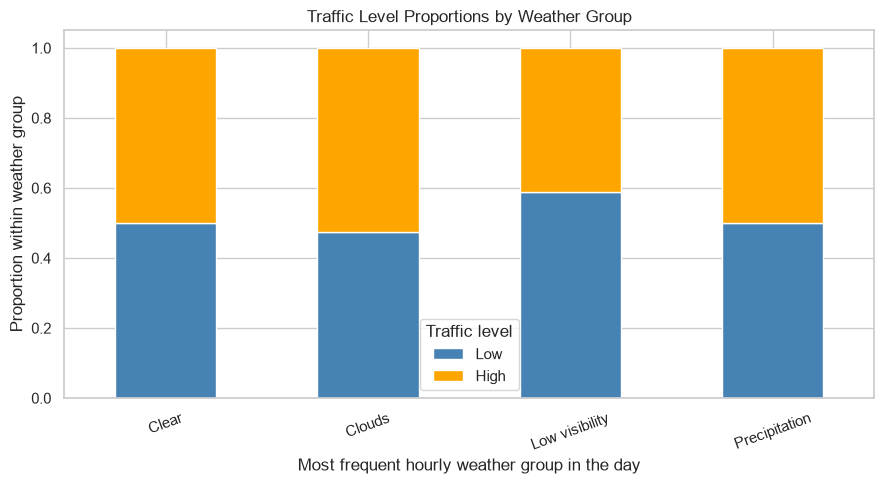

Thư mục hiện tại: c:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175\notebooks

NHẬN XÉT ĐỂ ĐƯA VÀO BÁO CÁO:
Kiểm định Chi-square cho χ² = 5.682, df = 3, p = 0.1282. Tần số kỳ vọng nhỏ nhất là 70.50; 0.0% số ô có tần số kỳ vọng dưới 5. Chưa đủ bằng chứng bác bỏ H₀. Không khẳng định hai biến chắc chắn độc lập. Cramér’s V = 0.068. Kết quả không chứng minh quan hệ nhân quả và có thể chịu ảnh hưởng của phụ thuộc thời gian, ngày trong tuần hoặc mùa.


In [9]:
# Chỉ dùng ngày có nhóm thời tiết xác định
chi_data = daily24.loc[
    daily24["weather_group"] != "Unknown"
].copy()

if chi_data.empty:
    raise ValueError("Không có ngày có nhóm thời tiết hợp lệ.")

# Ngưỡng được tính trên toàn bộ ngày đủ 24 giờ
threshold = daily24["daily_mean"].median()

chi_data["traffic_level"] = np.where(
    chi_data["daily_mean"] >= threshold,
    "High",
    "Low"
)

print(f"Ngưỡng chia High/Low: {threshold:.2f} xe/giờ")
print("Số ngày dùng cho Chi-square:", len(chi_data))
print(
    "Số ngày loại vì Unknown:",
    len(daily24) - len(chi_data)
)

observed = pd.crosstab(
    chi_data["weather_group"],
    chi_data["traffic_level"]
).reindex(columns=["Low", "High"], fill_value=0)

if observed.shape[0] < 2 or (observed.sum(axis=0) == 0).any():
    raise ValueError("Bảng chéo không đủ nhóm để kiểm định.")

print("\nBảng tần số quan sát:")
display(observed)

chi2, p_value, dof, expected = stats.chi2_contingency(
    observed,
    correction=False
)

expected_table = pd.DataFrame(
    expected,
    index=observed.index,
    columns=observed.columns
)

print("\nBảng tần số kỳ vọng:")
display(expected_table)

min_expected = expected.min()
small_ratio = (expected < 5).mean()

chi_valid = (
    min_expected >= 1
    and small_ratio <= 0.20
)

n = observed.to_numpy().sum()
k = min(observed.shape) - 1

cramers_v = np.sqrt(chi2 / (n * k))

chi_table = pd.DataFrame({
    "chi2": [chi2],
    "df": [dof],
    "p_value": [p_value],
    "n_days": [n],
    "median_threshold": [threshold],
    "min_expected": [min_expected],
    "percent_expected_under_5": [small_ratio * 100],
    "approximation_acceptable": [chi_valid],
    "cramers_v": [cramers_v]
})

display(chi_table)

if not chi_valid:
    chi_conclusion = (
        "Tần số kỳ vọng chưa đạt quy ước xấp xỉ; "
        "chưa kết luận theo p-value này."
    )
elif p_value < ALPHA:
    chi_conclusion = (
        "Bác bỏ H₀: có bằng chứng về mối liên hệ "
        "giữa nhóm thời tiết và mức lưu lượng."
    )
else:
    chi_conclusion = (
        "Chưa đủ bằng chứng bác bỏ H₀. "
        "Không khẳng định hai biến chắc chắn độc lập."
    )

print("\nKết luận:", chi_conclusion)

observed.to_csv(TABLE / "chi_square_observed.csv")
expected_table.to_csv(TABLE / "chi_square_expected.csv")
chi_table.to_csv(
    TABLE / "chi_square_results.csv",
    index=False
)

proportions = observed.div(
    observed.sum(axis=1),
    axis=0
)

proportions.to_csv(
    TABLE / "chi_square_proportions.csv"
)

proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["steelblue", "orange"]
)

plt.title("Traffic Level Proportions by Weather Group")
plt.xlabel("Most frequent hourly weather group in the day")
plt.ylabel("Proportion within weather group")
plt.xticks(rotation=20)
plt.legend(title="Traffic level")

save_plot("chi_square_proportions.png")

# In đoạn nhận xét theo kết quả mới để dùng trong báo cáo
print("\nNHẬN XÉT ĐỂ ĐƯA VÀO BÁO CÁO:")

print(
    f"Kiểm định Chi-square cho χ² = {chi2:.3f}, "
    f"df = {dof}, p = {p_value:.4g}. "
    f"Tần số kỳ vọng nhỏ nhất là {min_expected:.2f}; "
    f"{small_ratio:.1%} số ô có tần số kỳ vọng dưới 5. "
    f"{chi_conclusion} "
    f"Cramér’s V = {cramers_v:.3f}. "
    "Kết quả không chứng minh quan hệ nhân quả "
    "và có thể chịu ảnh hưởng của phụ thuộc thời gian, "
    "ngày trong tuần hoặc mùa."
)

### Nhận xét

Kết quả và kết luận được trình bày ở cuối cell code phía trên,
dựa trên cách nhóm thời tiết đã cập nhật.

High/Low là hai mức tương đối theo trung vị của mẫu,
không phải phân loại ùn tắc giao thông.
Cramér’s V được sử dụng để đánh giá độ lớn liên hệ bên cạnh p-value.

## 7. Tương quan Pearson và Spearman

### Quy tắc diễn giải hệ số tương quan

- Dấu dương (+): hai biến có xu hướng tăng cùng chiều.
- Dấu âm (−): một biến có xu hướng tăng khi biến kia giảm.
- Hệ số gần 0: không thể hiện mối liên hệ tuyến tính rõ ràng với Pearson; với Spearman, không thể hiện mối liên hệ đơn điệu rõ ràng.
- Trị tuyệt đối của hệ số càng lớn thì mối liên hệ theo dạng mà hệ số đo lường càng mạnh.

Để thống nhất cách trình bày, nhóm sử dụng quy ước tham khảo dựa trên trị tuyệt đối của hệ số:

| Trị tuyệt đối của hệ số | Mức độ tham khảo |
|---|---|
| 0,00 đến dưới 0,10 | Rất yếu |
| 0,10 đến dưới 0,30 | Yếu |
| 0,30 đến dưới 0,50 | Trung bình |
| 0,50 đến dưới 0,70 | Khá mạnh |
| Từ 0,70 đến 1,00 | Mạnh |

Đây là quy ước mô tả, không phải ngưỡng khoa học áp dụng cho mọi lĩnh vực.

Ma tran Pearson:


,temp_c,rain_1h,snow_1h,clouds_all,traffic_volume
temp_c,1.000000,0.061372,-0.016308,-0.109690,0.139226
rain_1h,0.061372,1.000000,0.000770,0.068333,-0.013393
snow_1h,-0.016308,0.000770,1.000000,0.024202,-0.002086
clouds_all,-0.109690,0.068333,0.024202,1.000000,0.078347
traffic_volume,0.139226,-0.013393,-0.002086,0.078347,1.000000


Ma tran Spearman:


,temp_c,rain_1h,snow_1h,clouds_all,traffic_volume
temp_c,1.000000,0.100514,-0.025625,-0.150185,0.140084
rain_1h,0.100514,1.000000,-0.002252,0.132058,0.004273
snow_1h,-0.025625,-0.002252,1.000000,0.032532,-0.005155
clouds_all,-0.150185,0.132058,0.032532,1.000000,0.072905
traffic_volume,0.140084,0.004273,-0.005155,0.072905,1.000000


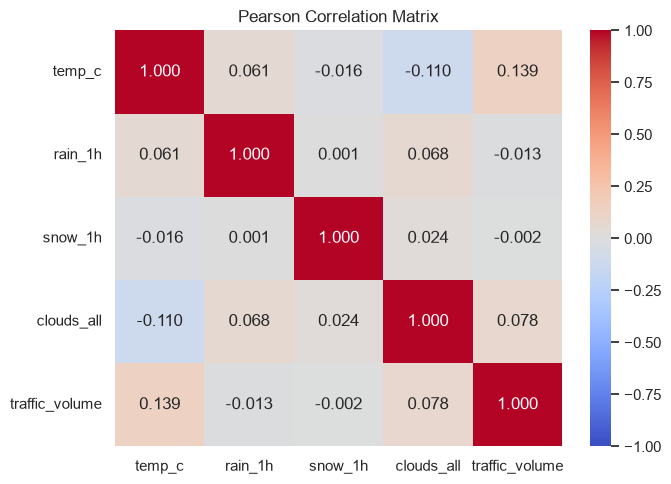

Thư mục hiện tại: c:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175\notebooks


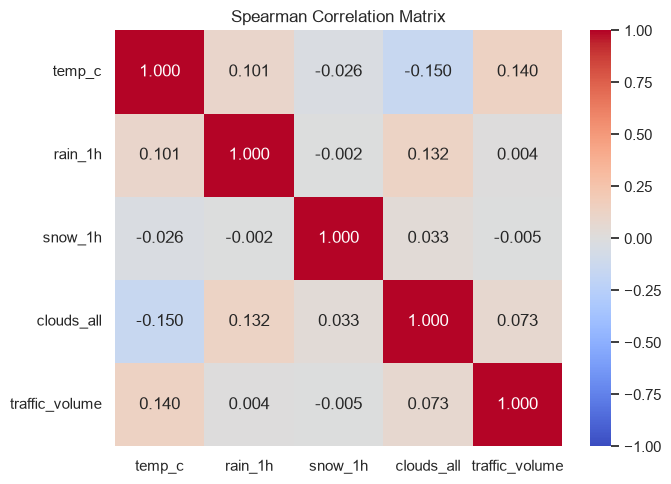

Thư mục hiện tại: c:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175\notebooks


,variable,n,pearson_r,pearson_p,spearman_rho,spearman_p,pearson_p_holm,spearman_p_holm
0,temp_c,40565,0.139226,1.098823e-174,0.140084,7.686600e-177,4.395293e-174,3.074640e-176
1,rain_1h,40574,-0.013393,6.978241e-03,0.004273,3.894609e-01,1.395648e-02,5.982566e-01
2,snow_1h,40575,-0.002086,6.743822e-01,-0.005155,2.991283e-01,6.743822e-01,5.982566e-01
3,clouds_all,40575,0.078347,2.851506e-56,0.072905,6.024598e-49,8.554519e-56,1.807379e-48


,variable,method,coefficient,direction,strength,p_value,p_holm,significance
0,temp_c,Pearson,0.139226,Thuận,Yếu,1.098823e-174,4.395293e-174,Có ý nghĩa thống kê sau hiệu chỉnh Holm
1,temp_c,Spearman,0.140084,Thuận,Yếu,7.686600e-177,3.074640e-176,Có ý nghĩa thống kê sau hiệu chỉnh Holm
2,rain_1h,Pearson,-0.013393,Nghịch,Rất yếu,6.978241e-03,1.395648e-02,Có ý nghĩa thống kê sau hiệu chỉnh Holm
3,rain_1h,Spearman,0.004273,Thuận,Rất yếu,3.894609e-01,5.982566e-01,Chưa đủ bằng chứng sau hiệu chỉnh Holm
4,snow_1h,Pearson,-0.002086,Nghịch,Rất yếu,6.743822e-01,6.743822e-01,Chưa đủ bằng chứng sau hiệu chỉnh Holm
5,snow_1h,Spearman,-0.005155,Nghịch,Rất yếu,2.991283e-01,5.982566e-01,Chưa đủ bằng chứng sau hiệu chỉnh Holm
6,clouds_all,Pearson,0.078347,Thuận,Rất yếu,2.851506e-56,8.554519e-56,Có ý nghĩa thống kê sau hiệu chỉnh Holm
7,clouds_all,Spearman,0.072905,Thuận,Rất yếu,6.024598e-49,1.807379e-48,Có ý nghĩa thống kê sau hiệu chỉnh Holm


In [10]:
corr_cols = [
    "temp_c", "rain_1h", "snow_1h",
    "clouds_all", "traffic_volume"
]

pearson_matrix = df[corr_cols].corr(method="pearson")
spearman_matrix = df[corr_cols].corr(method="spearman")

print("Ma tran Pearson:")
display(pearson_matrix)

print("Ma tran Spearman:")
display(spearman_matrix)

pearson_matrix.to_csv(TABLE / "pearson_matrix.csv")
spearman_matrix.to_csv(TABLE / "spearman_matrix.csv")

for name, matrix in [
    ("Pearson", pearson_matrix),
    ("Spearman", spearman_matrix)
]:
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".3f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1
    )
    plt.title(f"{name} Correlation Matrix")
    save_plot(f"{name.lower()}_heatmap.png")

rows = []

for col in corr_cols[:-1]:
    pair = df[[col, "traffic_volume"]].dropna()

    # Khong tinh he so neu mot bien khong co bien thien
    if len(pair) < 3 or (pair.nunique() < 2).any():
        rows.append({
            "variable": col,
            "n": len(pair),
            "pearson_r": np.nan,
            "pearson_p": np.nan,
            "spearman_rho": np.nan,
            "spearman_p": np.nan
        })
        continue

    pearson = stats.pearsonr(
        pair[col], pair["traffic_volume"]
    )
    spearman = stats.spearmanr(
        pair[col], pair["traffic_volume"]
    )

    rows.append({
        "variable": col,
        "n": len(pair),
        "pearson_r": pearson.statistic,
        "pearson_p": pearson.pvalue,
        "spearman_rho": spearman.statistic,
        "spearman_p": spearman.pvalue
    })

corr_results = pd.DataFrame(rows)

for method in ["pearson", "spearman"]:
    p_col = f"{method}_p"
    valid = corr_results[p_col].notna()

    corr_results[f"{method}_p_holm"] = np.nan

    if valid.any():
        corr_results.loc[valid, f"{method}_p_holm"] = (
            multipletests(
                corr_results.loc[valid, p_col],
                method="holm"
            )[1]
        )

display(corr_results)

corr_results.to_csv(
    TABLE / "correlations_with_traffic.csv", index=False
)

# Tạo bảng diễn giải tương quan dựa trên kết quả thực tế

def interpret_strength(r):
    if pd.isna(r):
        return "Không tính được"

    a = abs(r)

    if a < 0.10:
        return "Rất yếu"
    elif a < 0.30:
        return "Yếu"
    elif a < 0.50:
        return "Trung bình"
    elif a < 0.70:
        return "Khá mạnh"
    else:
        return "Mạnh"


def interpret_direction(r):
    if pd.isna(r):
        return "Không xác định"
    elif r > 0:
        return "Thuận"
    elif r < 0:
        return "Nghịch"
    else:
        return "Gần như không có chiều"


interpretation_rows = []

for _, row in corr_results.iterrows():
    for method in ["pearson", "spearman"]:
        coefficient_col = (
            "pearson_r" if method == "pearson"
            else "spearman_rho"
        )
        p_col = f"{method}_p"
        p_adjusted_col = f"{method}_p_holm"

        r = row[coefficient_col]
        p = row[p_col]
        p_adjusted = row[p_adjusted_col]

        if pd.isna(r) or pd.isna(p):
            significance = "Không đủ dữ liệu để kết luận"
        elif p_adjusted < ALPHA:
            significance = (
                "Có ý nghĩa thống kê sau hiệu chỉnh Holm"
            )
        else:
            significance = (
                "Chưa đủ bằng chứng sau hiệu chỉnh Holm"
            )

        interpretation_rows.append({
            "variable": row["variable"],
            "method": method.capitalize(),
            "coefficient": r,
            "direction": interpret_direction(r),
            "strength": interpret_strength(r),
            "p_value": p,
            "p_holm": p_adjusted,
            "significance": significance
        })

interpretation_table = pd.DataFrame(
    interpretation_rows
)

display(interpretation_table)

interpretation_table.to_csv(
    TABLE / "correlation_interpretation.csv",
    index=False
)

## 8. Scatter plot giữa thời tiết và lưu lượng

Vẽ scatter plot để quan sát xu hướng và độ phân tán. Mỗi hình lấy mẫu tối đa 8.000 điểm; hệ số tương quan vẫn tính trên toàn bộ cặp dữ liệu hợp lệ.

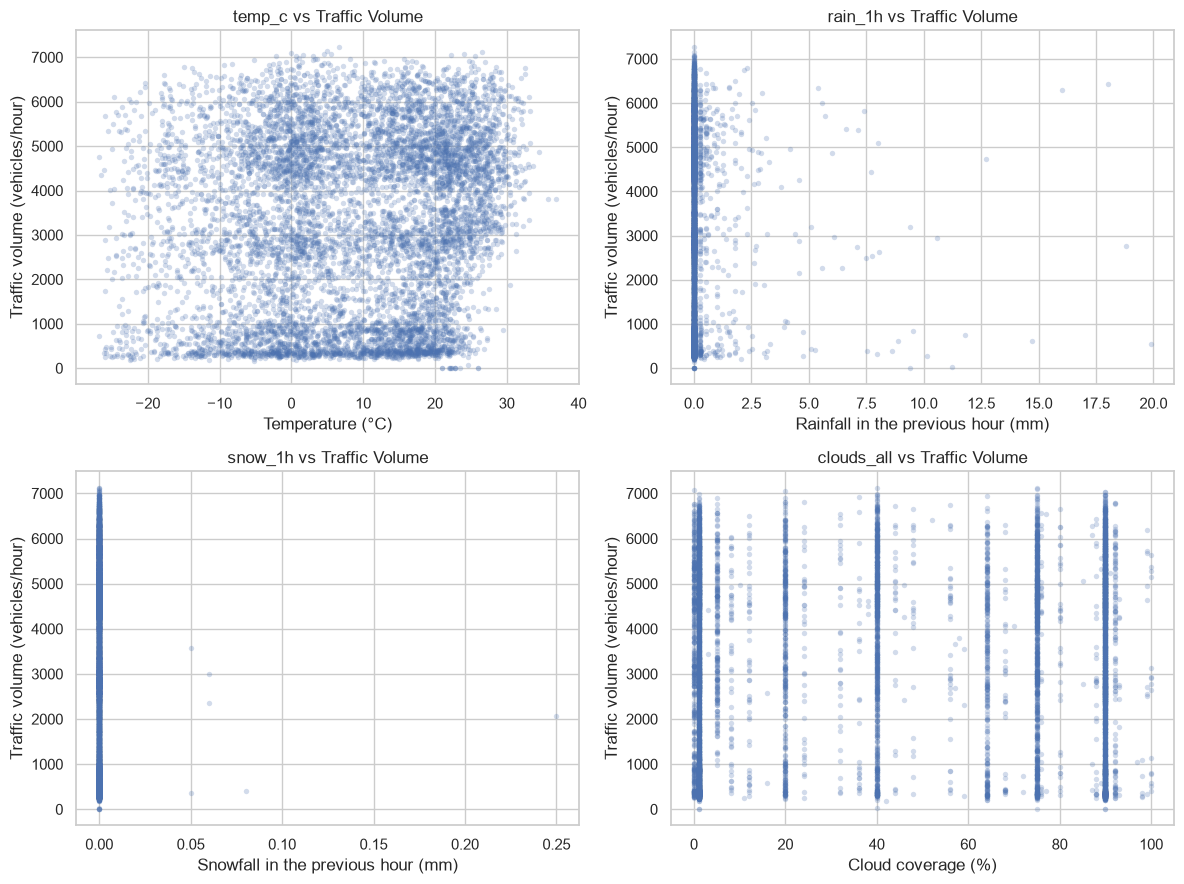

Thư mục hiện tại: c:\Users\PHUONG NHI\Downloads\524H0185_524H0073_524H0175\notebooks


In [11]:
labels = {
    "temp_c": "Temperature (°C)",
    "rain_1h": "Rainfall in the previous hour (mm)",
    "snow_1h": "Snowfall in the previous hour (mm)",
    "clouds_all": "Cloud coverage (%)"
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, col in zip(axes.flat, labels):
    plot_data = df[[col, "traffic_volume"]].dropna()

    if len(plot_data) > 8000:
        plot_data = plot_data.sample(n=8000, random_state=42)

    sns.scatterplot(
        data=plot_data,
        x=col,
        y="traffic_volume",
        alpha=0.25,
        s=15,
        linewidth=0,
        ax=ax
    )

    ax.set_title(f"{col} vs Traffic Volume")
    ax.set_xlabel(labels[col])
    ax.set_ylabel("Traffic volume (vehicles/hour)")

save_plot("weather_traffic_scatter.png")

### Nhận xét

Nhiệt độ có tương quan thuận yếu với lưu lượng (Pearson ≈ 0,139; Spearman ≈ 0,140). Mây có tương quan rất yếu; mưa và tuyết có hệ số gần 0. Các điểm phân tán rộng, cho thấy từng biến thời tiết riêng lẻ chưa giải thích rõ biến động lưu lượng. Tương quan không chứng minh nhân quả.

## 9. Hạn chế

Kiểm định chỉ sử dụng 1.214 ngày đủ dữ liệu, có thể ảnh hưởng tính đại diện. Các quan sát vẫn có thể phụ thuộc theo thời gian nên cần diễn giải p-value thận trọng. Thời tiết đại diện và cách chia High/Low làm mất một phần thông tin; mưa, tuyết có nhiều giá trị bằng 0.